# Online News Popularity Prediction: A Comparative Study of SVM and Decision Tree with PCA

## Phase 1 — Data audit and exploratory analysis

**Research question:** How effectively can SVM and Decision Tree classify online news popularity, and how does PCA affect predictive performance?

**Dataset:** `OnlineNewsPopularity.csv` (UCI Machine Learning Repository, Online News Popularity dataset). The reference study describes the Mashable articles and popularity prediction task (Fernandes, Vinagre & Cortez, 2015). Dataset download page: <https://archive.ics.uci.edu/dataset/332/online+news+popularity>.

**Target rule:** `popular = 1` when `shares > 1400`; otherwise `popular = 0`.

This notebook implements data inspection, target creation, EDA and a preliminary leakage audit only. **No classifiers are fitted, no cross-validation is run, and no PCA is fitted in Phase 1.** The four planned model comparisons (scaled SVM, scaled PCA + SVM, Decision Tree without PCA, scaled PCA + Decision Tree) belong to a later phase.

> Put the downloaded CSV at `data/OnlineNewsPopularity.csv` relative to the project root. The original dataset is not copied into the final submission ZIP (per project instructions).

## 1. Imports, environment and loading the dataset

In [1]:
from pathlib import Path
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.max_columns', 80)
pd.set_option('display.max_rows', 100)
sns.set_theme(style='whitegrid', context='notebook')

print(f'Python: {sys.version.split()[0]}')
for package, version in [
    ('pandas', pd.__version__), ('numpy', np.__version__),
    ('matplotlib', plt.matplotlib.__version__), ('seaborn', sns.__version__),
]:
    print(f'{package}: {version}')

candidate_paths = [
    Path('data/OnlineNewsPopularity.csv'),
    Path('../data/OnlineNewsPopularity.csv'),
]
DATA_PATH = next((p for p in candidate_paths if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError(
        'Dataset not found. Download OnlineNewsPopularity.csv from the UCI page '
        'linked above and place it in data/OnlineNewsPopularity.csv.'
    )

df_raw = pd.read_csv(DATA_PATH)
# The supplied CSV headers contain leading spaces; normalize header whitespace only.
df_raw.columns = df_raw.columns.str.strip()
print(f'Loaded: {DATA_PATH.resolve()}')
print(f'Shape: {df_raw.shape[0]:,} rows × {df_raw.shape[1]:,} columns')

Python: 3.9.12
pandas: 1.4.2
numpy: 1.21.5
matplotlib: 3.5.1
seaborn: 0.11.2
Loaded: /Users/yiluo/Desktop/DSA5101_proejct_Online-news-popularity-prediction-based-on-PCA-and-Decision-tree/data/OnlineNewsPopularity.csv
Shape: 39,644 rows × 61 columns


## 2. Dimensions, schema, missingness and duplicates

In [2]:
schema = pd.DataFrame({
    'dtype': df_raw.dtypes.astype(str),
    'non_null': df_raw.notna().sum(),
    'missing': df_raw.isna().sum(),
    'unique_values': df_raw.nunique(dropna=True),
}).sort_index()
display(schema)

print('Exact duplicate rows:', int(df_raw.duplicated().sum()))
if 'url' in df_raw.columns:
    print('Duplicate URL values:', int(df_raw['url'].duplicated().sum()))
print('Columns with missing values:', int((df_raw.isna().sum() > 0).sum()))
print('Total missing cells:', int(df_raw.isna().sum().sum()))

display(df_raw.describe(include='all').T)

,dtype,non_null,missing,unique_values
LDA_00,float64,39644,0,39337
LDA_01,float64,39644,0,39098
LDA_02,float64,39644,0,39525
LDA_03,float64,39644,0,38963
LDA_04,float64,39644,0,39370
abs_title_sentiment_polarity,float64,39644,0,653
abs_title_subjectivity,float64,39644,0,532
average_token_length,float64,39644,0,30136
avg_negative_polarity,float64,39644,0,13841
avg_positive_polarity,float64,39644,0,27301


Exact duplicate rows: 0
Duplicate URL values: 0
Columns with missing values: 0
Total missing cells: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
url,39644,39644,http://mashable.com/2013/01/07/amazon-instant-...,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
timedelta,39644.0,NaN,NaN,NaN,354.530471,214.163767,8.0,164.0,339.0,542.0,731.0
n_tokens_title,39644.0,NaN,NaN,NaN,10.398749,2.114037,2.0,9.0,10.0,12.0,23.0
n_tokens_content,39644.0,NaN,NaN,NaN,546.514731,471.107508,0.0,246.0,409.0,716.0,8474.0
n_unique_tokens,39644.0,NaN,NaN,NaN,0.548216,3.520708,0.0,0.47087,0.539226,0.608696,701.0
n_non_stop_words,39644.0,NaN,NaN,NaN,0.996469,5.231231,0.0,1.0,1.0,1.0,1042.0
n_non_stop_unique_tokens,39644.0,NaN,NaN,NaN,0.689175,3.264816,0.0,0.625739,0.690476,0.75463,650.0
num_hrefs,39644.0,NaN,NaN,NaN,10.88369,11.332017,0.0,4.0,8.0,14.0,304.0
num_self_hrefs,39644.0,NaN,NaN,NaN,3.293638,3.855141,0.0,1.0,3.0,4.0,116.0
num_imgs,39644.0,NaN,NaN,NaN,4.544143,8.309434,0.0,1.0,1.0,4.0,128.0


### Initial data-quality notes

The schema and summary above are computed directly from the supplied CSV. This phase reports missingness and duplicates but does not silently remove or impute rows. Header whitespace is normalized so column names are easier to use. The later modeling phase should make and document any further cleaning decisions based on these checks.

## 3. Target construction and class distribution

,class,definition,count,percentage
0,Unpopular (0),shares ≤ 1400,20082,50.655837
1,Popular (1),shares > 1400,19562,49.344163


Rows exactly at threshold (assigned unpopular): 1592
Observed shares median (descriptive only): 1400.0


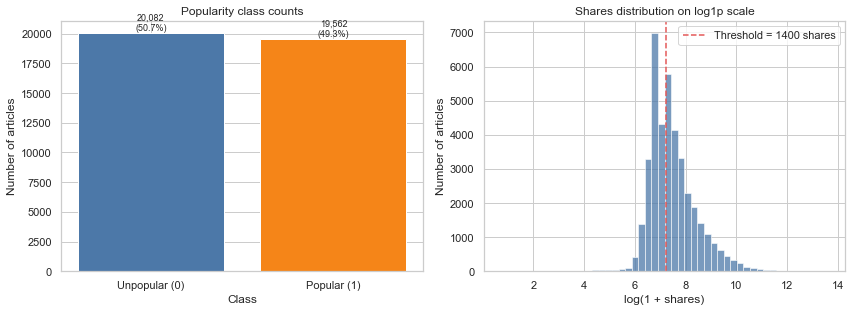

In [3]:
TARGET_SOURCE = 'shares'
POPULARITY_THRESHOLD = 1400
if TARGET_SOURCE not in df_raw.columns:
    raise KeyError(f'Required target column {TARGET_SOURCE!r} is absent.')

shares = pd.to_numeric(df_raw[TARGET_SOURCE], errors='coerce')
if shares.isna().any():
    raise ValueError('The shares target has missing or non-numeric values; resolve before labeling.')

df = df_raw.copy()
df['popular'] = (shares > POPULARITY_THRESHOLD).astype('int8')
class_counts = df['popular'].value_counts().reindex([0, 1], fill_value=0)
class_summary = pd.DataFrame({
    'class': ['Unpopular (0)', 'Popular (1)'],
    'definition': [f'shares ≤ {POPULARITY_THRESHOLD}', f'shares > {POPULARITY_THRESHOLD}'],
    'count': [int(class_counts.loc[0]), int(class_counts.loc[1])],
    'percentage': [100 * class_counts.loc[0] / len(df), 100 * class_counts.loc[1] / len(df)],
})
display(class_summary)
print('Rows exactly at threshold (assigned unpopular):', int((shares == POPULARITY_THRESHOLD).sum()))
print('Observed shares median (descriptive only):', float(shares.median()))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].bar(class_summary['class'], class_summary['count'],
           color=['#4C78A8', '#F58518'])
axes[0].set_title('Popularity class counts')
axes[0].set_xlabel('Class')
axes[0].set_ylabel('Number of articles')
for i, row in class_summary.iterrows():
    axes[0].text(i, row['count'], f"{row['count']:,}\n({row['percentage']:.1f}%)",
                 ha='center', va='bottom', fontsize=9)

sns.histplot(np.log1p(shares), bins=50, color='#4C78A8', ax=axes[1])
axes[1].axvline(np.log1p(POPULARITY_THRESHOLD), color='#E45756', linestyle='--',
                label=f'Threshold = {POPULARITY_THRESHOLD} shares')
axes[1].set_title('Shares distribution on log1p scale')
axes[1].set_xlabel('log(1 + shares)')
axes[1].set_ylabel('Number of articles')
axes[1].legend()
plt.tight_layout()
plt.show()

## 4. Define candidate predictors and exclude target/identifier

In [4]:
# `shares` defines the label and must never enter X. `url` is an article identifier,
# not a generalizable numeric/content predictor, and is excluded from the feature matrix.
EXCLUDED_COLUMNS = {'shares', 'popular', 'url'}
feature_columns = [c for c in df.columns if c not in EXCLUDED_COLUMNS]
X_eda = df[feature_columns].copy()
y = df['popular'].copy()

print(f'Candidate predictors: {X_eda.shape[1]}')
print('Excluded columns:', sorted(EXCLUDED_COLUMNS.intersection(df.columns)))
print('Identifier retained only for audit:', 'url' in df.columns)
display(pd.DataFrame({
    'feature': feature_columns,
    'dtype': X_eda.dtypes.astype(str).values,
    'n_unique': X_eda.nunique(dropna=True).values,
}).head(70))

Candidate predictors: 59
Excluded columns: ['popular', 'shares', 'url']
Identifier retained only for audit: True


,feature,dtype,n_unique
0,timedelta,float64,724
1,n_tokens_title,float64,20
2,n_tokens_content,float64,2406
3,n_unique_tokens,float64,27281
4,n_non_stop_words,float64,1451
5,n_non_stop_unique_tokens,float64,22930
6,num_hrefs,float64,133
7,num_self_hrefs,float64,59
8,num_imgs,float64,91
9,num_videos,float64,53


## 5. Exploratory feature analysis

Numeric candidate features: 59
Binary indicator features: 14
Other numeric features: 45


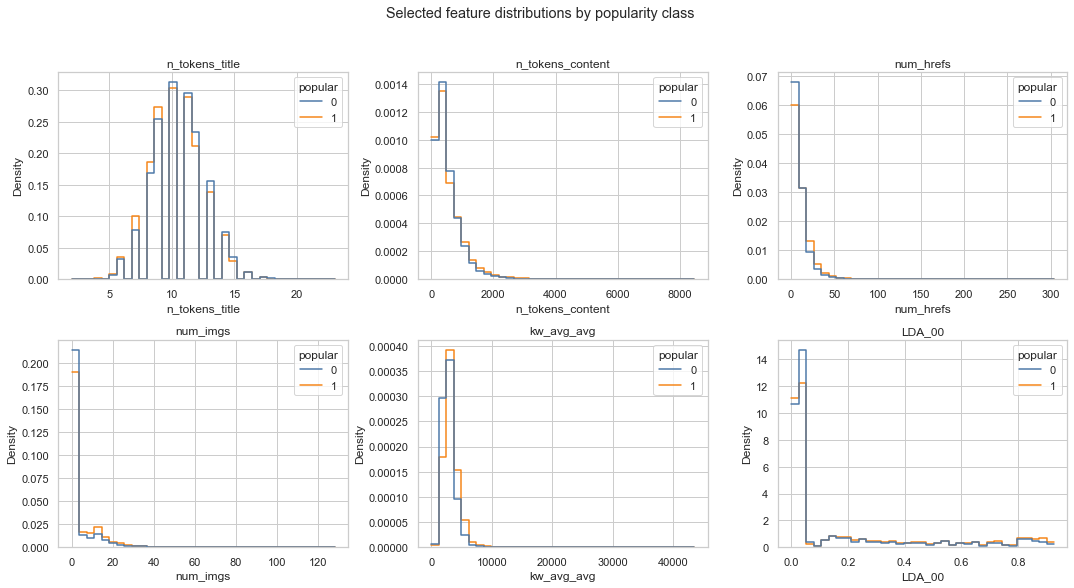

,Pearson correlation with popular label
kw_avg_avg,0.162057
LDA_02,-0.156471
data_channel_is_world,-0.150726
is_weekend,0.137616
data_channel_is_entertainment,-0.110558
data_channel_is_socmed,0.110144
weekday_is_saturday,0.106713
data_channel_is_tech,0.095336
kw_min_avg,0.092386
num_hrefs,0.088362


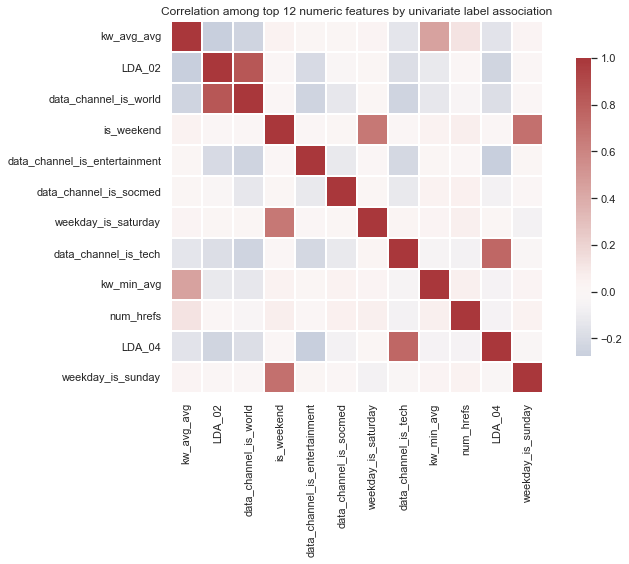

In [5]:
numeric_features = X_eda.select_dtypes(include=np.number).columns.tolist()
binary_features = [c for c in numeric_features if set(X_eda[c].dropna().unique()).issubset({0, 1})]
continuous_features = [c for c in numeric_features if c not in binary_features]
print(f'Numeric candidate features: {len(numeric_features)}')
print(f'Binary indicator features: {len(binary_features)}')
print(f'Other numeric features: {len(continuous_features)}')

# Distribution of selected continuous features. These plots are descriptive, not model selection.
preferred = ['n_tokens_title', 'n_tokens_content', 'num_hrefs', 'num_imgs',
             'kw_avg_avg', 'LDA_00', 'global_sentiment_polarity']
plot_features = [c for c in preferred if c in X_eda.columns]
if len(plot_features) < 4:
    plot_features += [c for c in continuous_features if c not in plot_features][:max(0, 6-len(plot_features))]
plot_features = plot_features[:6]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, plot_features):
    sns.histplot(data=df, x=col, hue='popular', bins=35, stat='density',
                 common_norm=False, element='step', fill=False, ax=ax,
                 palette={0: '#4C78A8', 1: '#F58518'})
    ax.set_title(col)
    ax.set_ylabel('Density')
for ax in axes.flat[len(plot_features):]:
    ax.set_visible(False)
fig.suptitle('Selected feature distributions by popularity class', y=1.02)
plt.tight_layout()
plt.show()

# Univariate association screen for numeric predictors. This is EDA only; it is not
# feature selection and must not be used to tune against the final test set.
numeric_assoc = X_eda[numeric_features].corrwith(y).dropna().sort_values(key=np.abs, ascending=False)
display(numeric_assoc.rename('Pearson correlation with popular label').to_frame().head(15))
top_corr_features = numeric_assoc.head(12).index.tolist()
if top_corr_features:
    corr = X_eda[top_corr_features].corr()
    plt.figure(figsize=(11, 8))
    sns.heatmap(corr, cmap='vlag', center=0, square=True, linewidths=.3,
                cbar_kws={'shrink': .8})
    plt.title('Correlation among top 12 numeric features by univariate label association')
    plt.tight_layout()
    plt.show()

**Interpretation guardrail:** correlations and class-conditioned histograms are exploratory associations. They do not establish causation, and the univariate ranking is not used here to select features. All candidate predictors are still subject to leakage and availability review before model development.

## 6. Preliminary data-leakage and feature-availability audit

In [6]:
audit_rows = [
    ('shares', 'Target source', 'Excluded from predictors; directly defines the label.'),
    ('url', 'Identifier', 'Excluded from predictors; may identify an article and encourage memorization.'),
    ('self_reference_*_shares', 'Potentially time-sensitive aggregate', 'Verify values use only shares of referenced articles available before the focal article prediction time.'),
    ('kw_*', 'Potentially time-sensitive aggregate', 'Verify keyword popularity aggregates are computed only from earlier articles; inspect the dataset construction/source.'),
    ('timedelta', 'Temporal field; semantics need confirmation', 'Confirm exact definition and whether it is available at the intended prediction time; preserve time ordering for future-time evaluation if applicable.'),
    ('remaining content/meta features', 'Availability review needed', 'Confirm each field is observable at the prediction point; do not infer availability from a column name alone.'),
]
leakage_audit = pd.DataFrame(audit_rows, columns=['field/group', 'risk category', 'Phase 1 review action'])
display(leakage_audit)

suspect_cols = [c for c in X_eda.columns if c.startswith('self_reference_') or c.startswith('kw_')]
print('Potentially time-sensitive columns present:', suspect_cols)
print('No feature is removed solely on the basis of this preliminary naming-based audit; confirm data provenance before modeling.')

,field/group,risk category,Phase 1 review action
0,shares,Target source,Excluded from predictors; directly defines the...
1,url,Identifier,Excluded from predictors; may identify an arti...
2,self_reference_*_shares,Potentially time-sensitive aggregate,Verify values use only shares of referenced ar...
3,kw_*,Potentially time-sensitive aggregate,Verify keyword popularity aggregates are compu...
4,timedelta,Temporal field; semantics need confirmation,Confirm exact definition and whether it is ava...
5,remaining content/meta features,Availability review needed,Confirm each field is observable at the predic...


Potentially time-sensitive columns present: ['kw_min_min', 'kw_max_min', 'kw_avg_min', 'kw_min_max', 'kw_max_max', 'kw_avg_max', 'kw_min_avg', 'kw_max_avg', 'kw_avg_avg', 'self_reference_min_shares', 'self_reference_max_shares', 'self_reference_avg_sharess']
No feature is removed solely on the basis of this preliminary naming-based audit; confirm data provenance before modeling.


### Leakage controls for the next phase

- Split the data before any learned preprocessing. Fit `StandardScaler` and PCA inside each training fold using a pipeline.
- Keep the final test set out of hyperparameter selection, threshold selection, and feature selection.
- The classification label threshold is fixed in advance at 1,400 shares; it is not recalculated from the test set.
- Confirm whether `self_reference_*_shares` and `kw_*` features are genuinely available before prediction. If this cannot be established, exclude them from the primary pre-publication model and treat their inclusion only as a clearly labeled sensitivity analysis.
- Consider a chronological split if the intended claim is prediction of future articles. The exact meaning of `timedelta` must be confirmed from dataset documentation before using it as a split key.

## 7. Phase 1 summary and reproducibility record

In [7]:
print('Phase 1 completion record')
print(f'- Dataset file: {DATA_PATH.name}')
print(f'- Rows × original columns: {df_raw.shape[0]:,} × {df_raw.shape[1]:,}')
print(f'- Candidate predictors after exclusions: {X_eda.shape[1]}')
print(f'- Missing cells: {int(df_raw.isna().sum().sum()):,}')
print(f'- Exact duplicate rows: {int(df_raw.duplicated().sum()):,}')
print(f'- Target rule: popular = 1 iff shares > {POPULARITY_THRESHOLD}; otherwise 0')
print(f'- Class counts: unpopular={int(class_counts.loc[0]):,}; popular={int(class_counts.loc[1]):,}')
print('- Models trained: none')
print('- PCA fitted: no')

Phase 1 completion record
- Dataset file: OnlineNewsPopularity.csv
- Rows × original columns: 39,644 × 61
- Candidate predictors after exclusions: 59
- Missing cells: 0
- Exact duplicate rows: 0
- Target rule: popular = 1 iff shares > 1400; otherwise 0
- Class counts: unpopular=20,082; popular=19,562
- Models trained: none
- PCA fitted: no


### References

- Fernandes, K., Vinagre, P., & Cortez, P. (2015). *A Proactive Intelligent Decision Support System for Predicting the Popularity of Online News*. EPIA 2015, LNAI 9273, 535–546. https://doi.org/10.1007/978-3-319-23485-4_53
- UCI Machine Learning Repository. *Online News Popularity*. https://archive.ics.uci.edu/dataset/332/online+news+popularity
- Course project requirements: `instructions/project_requirements.md`.